In [ ]:
# Exécuter seulement dans Google Colab
!pip install myqlm -q -q

# Introduction
Ce TP est basé sur le framework `MyQLM`, dont le code et la documentation sont disponibles sur cette [page GitHub](https://myqlm.github.io/). L'objectif de la séance est d'implémenter l'algorithme de recherche de Grover.

In [ ]:
# Lire cette cellule, puis l'exécuter sans modification.
import numpy as np
from qat.lang import QRoutine, H, CNOT, RY, Z, X, CCNOT, Program
from qat.qpus import get_default_qpu

qpu = get_default_qpu()

def display_result(circuit, nbshots=0, idx=None):
  '''
  Utilitary function to provide a nice display of the circuits.
  '''
  result = qpu.submit(circuit.to_job(nbshots=nbshots, qubits=idx)) # Objet de la classe Result
  if nbshots:
      tmp = {}
      for sample in result:
          state = sample.state
          if not state in tmp:
              tmp[state] = 0.
          tmp[sample.state] += sample.probability
      for state, proba in tmp.items():
          print(f"État {state}: probabilité {proba:.3f}")
  else:
      for sample in result:
          if sample.amplitude is None: # No amplitude when only a subset of qubits is measured
              print(f"État {sample.state}: probabilité {sample.probability:.3f}")
          else:
              print(f"État {sample.state}: probabilité {sample.probability:.3f}, amplitude {sample.amplitude:.3f}")

# Description de l'algorithme

L'[algorithme de Grover](https://fr.wikipedia.org/wiki/Algorithme_de_Grover) (Lov Grover, 1996) recherche un ou plusieurs éléments vérifiant un critère dans une liste **non triée** de longueur $N=2^n$, en $O(\sqrt{N})$ opérations au lieu de $O(N)$ classiquement.

Il se décompose en 3 étapes :
1. **Superposition** : des portes $H$ créent une superposition uniforme de toutes les entrées possibles du registre $x$.
2. **Marquage** : un **oracle** marque les éléments qui vérifient le critère.
3. **Amplification** : l'**opérateur de diffusion** amplifie l'amplitude (donc la probabilité) des états marqués.

Les étapes 2 et 3 sont répétées environ $\frac{\pi}{4}\sqrt{2^n}$ fois, puis on mesure. Le circuit annoté est le suivant :

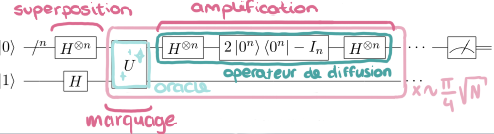

L'évolution de l'algorithme se visualise avec un histogramme des amplitudes :
- le **marquage** applique une phase $-1$ à l'état recherché : son amplitude devient négative, ce qui abaisse la moyenne des amplitudes ;
- la **diffusion** effectue une symétrie des amplitudes par rapport à cette moyenne : l'amplitude d'un état non recherché diminue, celle d'un état recherché repasse dans le positif et augmente.

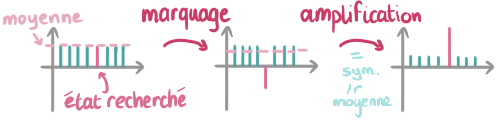

Chaque itération amplifie un peu plus l'état recherché au détriment des autres, ce qui augmente la probabilité de le mesurer.

# Implémentation de l'algorithme

On implémente d'abord chaque sous-bloc de l'algorithme, puis on les combine.

## Superposition

**Question 1.** Implémenter la routine qui crée une superposition uniforme sur $n$ qubits.

In [ ]:
def superposition(n):
    # Routine creation
    rout = QRoutine()

    # <<< COMPLETE HERE >>>

    return rout

On vérifie le résultat sur $n=3$ qubits.

In [ ]:
circuit = superposition(3).to_circ()
display_result(circuit)

## Marquage

On implémente deux oracles de marquage pour tester l'algorithme. Une porte NOT multi-contrôlée s'applique avec l'instruction

<center>
    X.ctrl(num_controls)(ctrl_qubits, target_qubit)
</center>

Par exemple, `X.ctrl(3)(q0, q1, q2, q3)` applique une porte $X$ sur `q3`, contrôlée par `q0`, `q1` et `q2`.

À partir d'une fonction de marquage
$$
f(x) = \begin{cases} 0 & \text{si } x \text{ n'est pas recherché} \\ 1 & \text{si } x \text{ est recherché} \end{cases}
$$
on veut construire un oracle $U$ tel que
$$
U \vert x \rangle = (-1)^{f(x)} \vert x \rangle.
$$
Pour cela, on procède en deux temps :
- construire une routine $U_f$ qui implémente $\vert x \rangle \vert y \rangle \rightarrow \vert x \rangle \vert y \oplus f(x) \rangle$ ;
- utiliser $U_f$ pour construire $U$.

### Fonction 1

Le circuit suivant applique la fonction 1, avec une entrée $x$ sur 4 qubits et une sortie $y$ sur 1 qubit.

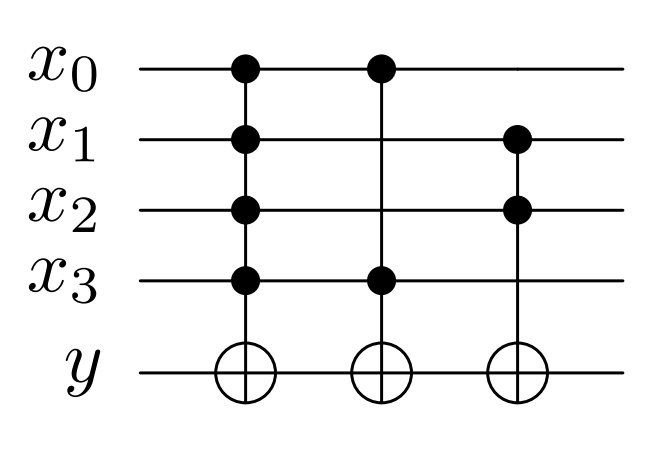

**Question 2.** À la main, retrouver les valeurs de $x$ recherchées (pour lesquelles $y = 1$ en sortie).

*RÉPONSE*

**Question 3.** Implémenter le circuit correspondant à la fonction 1 et vérifier qu'il correspond bien à celui donné ci-dessus.

In [ ]:
def function_1():
    # Routine creation
    rout = QRoutine()

    # <<< COMPLETE HERE >>>

    return rout

function_1().display()

**Question 4.** Vérifier la réponse à la question 2 en simulant le circuit pour toutes les valeurs possibles de $x$.

In [ ]:
# <<< COMPLETE HERE >>>

### Fonction 2

Le circuit suivant applique la fonction 2.

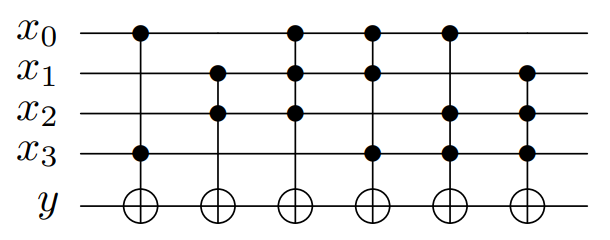

**Question 5.** À la main, retrouver les valeurs de $x$ recherchées (pour lesquelles $y=1$).

*RÉPONSE*

**Question 6.** Implémenter le circuit correspondant à la fonction 2 et vérifier qu'il correspond bien à celui ci-dessus.

In [ ]:
def function_2():
    # Routine creation
    rout = QRoutine()

    # <<< COMPLETE HERE >>>

    return rout

function_2().display()

**Question 7.** Vérifier la réponse à la question 5 en simulant le circuit pour toutes les valeurs possibles de $x$.

In [ ]:
# <<< COMPLETE HERE >>>

### Oracle de marquage

Il faut maintenant construire, à partir des fonctions $f_1$ et $f_2$, un oracle $U$ tel que $U \vert x \rangle = (-1)^{f(x)} \vert x \rangle$, c'est-à-dire une phase $-1$ si $f(x)=1$ et rien sinon. La porte $Z$ convient : $Z \vert 0 \rangle = \vert 0 \rangle$ et $Z \vert 1 \rangle = -\vert 1 \rangle$.

L'oracle se construit en 4 étapes :
0. l'état initial est $\vert x \rangle \vert y=0 \rangle$ ;
1. on applique la fonction $f$ pour obtenir $\vert x \rangle \vert f(x) \rangle$ ;
2. on applique une porte $Z$ sur le qubit $y$, ce qui ajoute une phase uniquement sur les états marqués ;
3. on applique l'inverse de $f$ pour remettre $y$ dans l'état $\vert 0 \rangle$.

En sortie, les états marqués portent la phase voulue, et le qubit ancillaire $y$ est toujours à 0 : on peut l'ignorer par la suite.

L'inverse d'une routine s'obtient avec la méthode `dag` :

<center>
    my_routine.dag()(qubits)
</center>

**Question 8.** Implémenter la routine `marking_oracle` en suivant ces étapes.

In [ ]:
def marking_oracle(function):
    # Routine creation
    rout = QRoutine()

    # <<< COMPLETE HERE >>>

    return rout

**Question 9.** Vérifier par simulation que l'oracle de marquage applique bien une phase $-1$ sur les amplitudes des états marqués des fonctions 1 et 2.

In [ ]:
# Function 1
# <<< COMPLETE HERE >>>

In [ ]:
# Function 2
# <<< COMPLETE HERE >>>

## Amplification

Il reste à amplifier les états marqués avec l'opérateur de diffusion. Sur $n$ qubits, il correspond au circuit suivant :

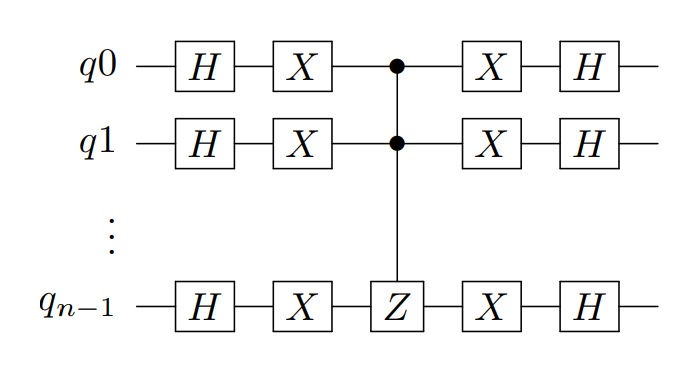

**Question 10.** Implémenter la routine `diffusion_operator` de paramètre $n$.

In [ ]:
def diffusion_operator(n):
    # Routine creation
    rout = QRoutine()

    # <<< COMPLETE HERE >>>

    return rout

## Algorithme de Grover

Avec toutes les routines précédentes, on peut implémenter l'algorithme de Grover, dont le circuit complet était donné en intro.

**Question 11.** Créer la routine `grover` qui prend en entrée un oracle et un nombre de qubits $n$ (qubit ancillaire $y$ inclus).

In [ ]:
def grover(oracle, n):
    # Routine creation
    rout = QRoutine()

    # <<< COMPLETE HERE >>>

    return rout

On vérifie qu'on retrouve bien les états recherchés pour les fonctions 1 et 2.

In [ ]:
n = 4

oracle_1 = marking_oracle(function_1())
circuit_1 = grover(oracle_1, n+1).to_circ()

display_result(circuit_1, idx=[0,1,2,3])

In [ ]:
n = 4

oracle_2 = marking_oracle(function_2())
circuit_2 = grover(oracle_2, n+1).to_circ()

display_result(circuit_2, idx=[0,1,2,3])